# CSE 4095 Class 7: Exploring Student Habits with Pandas

Dataset: `class1_student_habits.csv`, one row per student.

**In Colab:** upload the CSV to the Files sidebar before running, then use *Runtime > Run all*.

## Part 1: Loading and Inspecting the Data

**Q: What is a Pandas DataFrame?**

A Pandas Dataframe is a 2 dimensional, labeled, tabular structure.

### Dataset loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# "None" is a real category in prior_programming_experience (None/Some/Strong).
# pandas treats the string "None" as missing by default, which would silently
# delete 88 valid answers, so only blank cells count as missing here.
df = pd.read_csv("class1_student_habits.csv", keep_default_na=False, na_values=[""])


def header(title):
    """Print a labeled divider so each block of output explains itself."""
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)

### Dataset inspection

In [2]:
header("FIRST 5 ROWS (one row = one student)")
display(df.head())


FIRST 5 ROWS (one row = one student)


,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


**Q: What does one row represent in this dataset?**

One row represents A student

**Q: What does one column represent?**

One column represents an attribute value

In [3]:
header("DATASET SIZE")
print(f"Rows    (students in the dataset): {df.shape[0]}")
print(f"Columns (variables recorded):      {df.shape[1]}")


DATASET SIZE
Rows    (students in the dataset): 250
Columns (variables recorded):      10


In [4]:
header("COLUMN NAMES")
for i, name in enumerate(df.columns):
    print(f"Column {i}: {name}")


COLUMN NAMES
Column 0: student_id
Column 1: study_hours_per_week
Column 2: sleep_hours_per_night
Column 3: attendance_rate
Column 4: practice_problems_per_week
Column 5: prior_programming_experience
Column 6: study_group
Column 7: commute_minutes
Column 8: quiz_average
Column 9: exam_score


## Part 2: Column Types and Missing Values

In [5]:
identifier  = ["student_id"]
numerical   = ["study_hours_per_week", "sleep_hours_per_night", "attendance_rate",
               "practice_problems_per_week", "commute_minutes",
               "quiz_average", "exam_score"]
categorical = ["prior_programming_experience", "study_group"]

header("COLUMN CLASSIFICATION")
print(f"Identifier  ({len(identifier)}): {', '.join(identifier)}")
print(f"   -> {df['student_id'].nunique()} unique IDs for {len(df)} rows, so it labels")
print(f"      rows rather than measuring anything. Exclude it from statistics.\n")

print(f"Numerical   ({len(numerical)}):")
for c in numerical:
    print(f"   - column {df.columns.get_loc(c)}: {c:<28} {df[c].dtype}")

print(f"\nCategorical ({len(categorical)}):")
for c in categorical:
    print(f"   - column {df.columns.get_loc(c)}: {c:<28} {df[c].nunique()} categories")


COLUMN CLASSIFICATION
Identifier  (1): student_id
   -> 250 unique IDs for 250 rows, so it labels
      rows rather than measuring anything. Exclude it from statistics.

Numerical   (7):
   - column 1: study_hours_per_week         float64
   - column 2: sleep_hours_per_night        float64
   - column 3: attendance_rate              float64
   - column 4: practice_problems_per_week   int64
   - column 7: commute_minutes              int64
   - column 8: quiz_average                 float64
   - column 9: exam_score                   float64

Categorical (2):
   - column 5: prior_programming_experience 3 categories
   - column 6: study_group                  2 categories


In [6]:
header("CATEGORY BREAKDOWN (categorical columns)")

for c in categorical:
    counts = df[c].value_counts(dropna=False)
    labels = ["(blank - missing)" if pd.isna(v) else v for v in counts.index]
    table = pd.DataFrame({
        "category": labels,
        "students": counts.values,
        "percent_of_250": (counts.values / len(df) * 100).round(1),
    })
    print(f"\n{c}  -  how many students gave each answer:")
    print(table.to_string(index=False))


CATEGORY BREAKDOWN (categorical columns)

prior_programming_experience  -  how many students gave each answer:
         category  students  percent_of_250
             Some       107            42.8
             None        88            35.2
           Strong        48            19.2
(blank - missing)         7             2.8

study_group  -  how many students gave each answer:
category  students  percent_of_250
     Yes       129            51.6
      No       121            48.4


### Missing-value investigation

Only blank cells count as missing. No rows are deleted; each statistic below skips blanks column by column.

In [7]:
header("DATA TYPE AND MISSING VALUES, BY COLUMN")
print("'missing' counts blank cells only. No rows are deleted.\n")

summary = pd.DataFrame({
    "dtype": df.dtypes,
    "non_null_count": df.notna().sum(),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
summary.index.name = "column"
display(summary)

total_missing = int(df.isna().sum().sum())
n_cols_missing = int((df.isna().sum() > 0).sum())
print(f"{total_missing} missing cells in total, spread across "
      f"{n_cols_missing} of the {df.shape[1]} columns.")
print(f"That is {total_missing} of {df.size} total cells "
      f"({total_missing / df.size * 100:.2f}%).")


DATA TYPE AND MISSING VALUES, BY COLUMN
'missing' counts blank cells only. No rows are deleted.



,dtype,non_null_count,missing_count,missing_percent
column,,,,
student_id,str,250,0,0.0
study_hours_per_week,float64,241,9,3.6
sleep_hours_per_night,float64,238,12,4.8
attendance_rate,float64,250,0,0.0
practice_problems_per_week,int64,250,0,0.0
prior_programming_experience,str,243,7,2.8
study_group,str,250,0,0.0
commute_minutes,int64,250,0,0.0
quiz_average,float64,250,0,0.0


28 missing cells in total, spread across 3 of the 10 columns.
That is 28 of 2500 total cells (1.12%).


**Q: Which columns are numerical?**

Columns 1, 2, 3, 4, 7, 8, 9 are numerical

**Q: Which columns are categorical?**

Columns 5, and 6 are categorical

**Q: Which column is an identifier?**

Column 0 is an identifier

**Q: Which columns contain missing values?**

Columns 1, 2 and 5 are missing values

## Part 3: Descriptive Statistics

In [8]:
header("DESCRIPTIVE STATISTICS (numerical columns)")
print("'count' is the number of students with a value for that column,")
print("so a count below 250 means that column has blanks. Nothing was dropped.\n")

stats = df[numerical].describe().T[["count", "mean", "50%", "std", "min", "max"]]
stats = stats.rename(columns={"50%": "median"}).round(2)
stats["count"] = stats["count"].astype(int)
stats.index.name = "column"
display(stats)


DESCRIPTIVE STATISTICS (numerical columns)
'count' is the number of students with a value for that column,
so a count below 250 means that column has blanks. Nothing was dropped.



,count,mean,median,std,min,max
column,,,,,,
study_hours_per_week,241,7.50,7.50,2.94,0.3,17.8
sleep_hours_per_night,238,7.00,7.10,1.04,4.3,10.0
attendance_rate,250,85.47,85.75,9.58,54.4,100.0
practice_problems_per_week,250,16.86,16.00,9.56,0.0,78.0
commute_minutes,250,24.43,23.00,18.11,0.0,145.0
quiz_average,250,77.77,77.10,10.52,49.3,100.0
exam_score,250,77.16,76.95,10.33,51.4,100.0


In [9]:
header("FULL FIVE-NUMBER SUMMARY (quartiles included)")
print("Compare mean vs 50% (median): a mean well above the median means right-skew,")
print("usually caused by a few unusually large values.\n")
display(df[numerical].describe().round(2))


FULL FIVE-NUMBER SUMMARY (quartiles included)
Compare mean vs 50% (median): a mean well above the median means right-skew,
usually caused by a few unusually large values.



column,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,commute_minutes,quiz_average,exam_score
count,241.00,238.00,250.00,250.00,250.00,250.00,250.00
mean,7.50,7.00,85.47,16.86,24.43,77.77,77.16
std,2.94,1.04,9.58,9.56,18.11,10.52,10.33
min,0.30,4.30,54.40,0.00,0.00,49.30,51.40
25%,5.30,6.20,78.90,11.00,11.25,70.18,69.50
50%,7.50,7.10,85.75,16.00,23.00,77.10,76.95
75%,9.50,7.70,92.57,23.00,36.00,84.60,84.98
max,17.80,10.00,100.00,78.00,145.00,100.00,100.00


### Three Interesting Observations

1. The mean for the quiz scores, and the exam scores are very similar. Quiz scores being 77.77, and exam scores being 77.16. This means that overall, the quiz scores tend to give an idea as to what the exam scores will be

2. The std is also very similar for quiz and exam scores. Quiz std = 10.52, exam std = 10.33 (std is deviation, how much data deviates from the averaged trend)

3. The minimum hours slept being 4.30 is interesting, and I think that this student getting a higher quiz score than exam score is interesting, and likely due to lack of sleep before the exam compared to the quiz.

## Part 4: Filtering, Sorting, and Grouping

### A. Filtering: at least 10 study hours per week and at least 90% attendance

In [10]:
header("A. HIGH-EFFORT STUDENTS (>= 10 study hrs/week AND >= 90% attendance)")

high_effort = df[(df["study_hours_per_week"] >= 10) & (df["attendance_rate"] >= 90)]

cols_a = ["student_id", "study_hours_per_week", "attendance_rate",
          "practice_problems_per_week", "prior_programming_experience",
          "study_group", "quiz_average", "exam_score"]

print(f"{len(high_effort)} of {len(df)} students meet both conditions "
      f"({len(high_effort) / len(df) * 100:.1f}%).")
print(f"Their mean exam score: {high_effort['exam_score'].mean():.2f}")
print(f"Everyone else's:       {df.loc[~df.index.isin(high_effort.index), 'exam_score'].mean():.2f}")

# A blank study_hours value fails the >= test, so those students are excluded
# rather than counted as not qualifying. Report how many that affects.
unknown = df["study_hours_per_week"].isna() & (df["attendance_rate"] >= 90)
print(f"\nNote: {unknown.sum()} student(s) had >= 90% attendance but a blank")
print("study_hours_per_week, so they could not be evaluated either way.")

display(high_effort[cols_a].sort_values("exam_score", ascending=False))


A. HIGH-EFFORT STUDENTS (>= 10 study hrs/week AND >= 90% attendance)
16 of 250 students meet both conditions (6.4%).
Their mean exam score: 86.88
Everyone else's:       76.49

Note: 1 student(s) had >= 90% attendance but a blank
study_hours_per_week, so they could not be evaluated either way.


column,student_id,study_hours_per_week,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,quiz_average,exam_score
108,S109,10.1,91.6,25,None,Yes,94.1,100.0
119,S120,11.0,90.7,8,Some,Yes,95.0,98.8
167,S168,11.8,100.0,19,Some,Yes,98.3,97.2
168,S169,12.3,93.2,21,Some,Yes,94.1,96.8
204,S205,11.0,100.0,22,None,Yes,88.0,96.3
41,S042,10.7,98.2,23,Strong,No,100.0,96.2
63,S064,11.7,94.6,42,Some,Yes,93.7,94.1
195,S196,12.5,99.3,17,None,Yes,100.0,89.7
189,S190,13.7,91.3,9,Some,No,100.0,89.5
227,S228,11.4,95.4,16,Some,Yes,84.5,89.2


### B. Sorting: the 10 highest exam scores

In [11]:
header("B. TOP 10 EXAM SCORES")

cols_b = ["student_id", "exam_score", "quiz_average", "study_hours_per_week",
          "attendance_rate", "practice_problems_per_week",
          "sleep_hours_per_night", "prior_programming_experience", "study_group"]

top10 = df.nlargest(10, "exam_score")[cols_b]
display(top10.reset_index(drop=True))

print("Top-10 averages vs the whole class:")
for c in ["exam_score", "quiz_average", "study_hours_per_week",
          "attendance_rate", "practice_problems_per_week"]:
    print(f"  {c:<28} top 10: {top10[c].mean():>6.2f}    class: {df[c].mean():>6.2f}")


B. TOP 10 EXAM SCORES


column,student_id,exam_score,quiz_average,study_hours_per_week,attendance_rate,practice_problems_per_week,sleep_hours_per_night,prior_programming_experience,study_group
0,S004,100.0,86.4,10.8,77.1,16,7.6,Strong,No
1,S109,100.0,94.1,10.1,91.6,25,7.3,None,Yes
2,S224,100.0,83.4,16.2,84.7,13,8.1,Some,No
3,S216,99.0,96.4,9.0,100.0,15,7.6,Strong,No
4,S120,98.8,95.0,11.0,90.7,8,6.2,Some,Yes
5,S144,97.5,88.1,9.1,96.6,16,7.8,Some,No
6,S168,97.2,98.3,11.8,100.0,19,7.2,Some,Yes
7,S169,96.8,94.1,12.3,93.2,21,8.0,Some,Yes
8,S140,96.6,92.3,7.3,100.0,31,7.0,Strong,Yes
9,S232,96.5,84.5,5.1,93.4,15,7.1,Strong,No


Top-10 averages vs the whole class:
  exam_score                   top 10:  98.24    class:  77.16
  quiz_average                 top 10:  91.26    class:  77.77
  study_hours_per_week         top 10:  10.27    class:   7.50
  attendance_rate              top 10:  92.73    class:  85.47
  practice_problems_per_week   top 10:  17.90    class:  16.86


### C. Grouping: exam scores by study-group participation

In [12]:
header("C. EXAM SCORE BY STUDY-GROUP PARTICIPATION")

by_group = df.groupby("study_group")["exam_score"].agg(
    n_students="count",
    mean_exam="mean",
    median_exam="median",
    std_exam="std",
    min_exam="min",
    max_exam="max",
).round(2)
display(by_group)

gap = by_group.loc["Yes", "mean_exam"] - by_group.loc["No", "mean_exam"]
print(f"Difference in mean exam score (Yes - No): {gap:+.2f} points")
print(f"Standard deviation within each group:     ~{df['exam_score'].std():.2f} points")
print("The gap is far smaller than the spread inside either group.")


C. EXAM SCORE BY STUDY-GROUP PARTICIPATION


,n_students,mean_exam,median_exam,std_exam,min_exam,max_exam
study_group,,,,,,
No,121,76.87,75.9,10.41,51.4,100.0
Yes,129,77.43,77.7,10.29,55.9,100.0


Difference in mean exam score (Yes - No): +0.56 points
Standard deviation within each group:     ~10.33 points
The gap is far smaller than the spread inside either group.


In [13]:
# The two groups may differ in other habits as well, which is why a raw gap
# cannot be read as an effect of the study group itself.
header("C (cont.) OTHER HABITS BY GROUP - possible confounders")
display(df.groupby("study_group")[numerical].mean().round(2))


C (cont.) OTHER HABITS BY GROUP - possible confounders


column,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,commute_minutes,quiz_average,exam_score
study_group,,,,,,,
No,7.25,7.07,85.51,16.71,22.83,76.84,76.87
Yes,7.74,6.94,85.43,16.99,25.93,78.65,77.43


**Q: What do you observe from the group comparison?**

From the group comparison, I notice that students that study within a study group don't perform noticeably better than those that do not. Those that do study there is only a .56 different in exam scores. This difference is too small to attribute it directly to study groups. Even if the difference was larger, it could be multiple varying factors affecting the exam scores, such as willingness to study, and active retention of information / studying tactics.

## Part 5: Visualizations

The cell below sets up one shared look for every chart, so each one gets a title, a subtitle, and labeled axes.

In [14]:
# One palette, defined once, used by every figure.
SURFACE   = "#fcfcfb"   # chart background
PRIMARY   = "#0b0b0b"   # title ink
SECONDARY = "#52514e"   # subtitle ink
MUTED     = "#898781"   # axis labels and ticks
GRID      = "#e1e0d9"   # hairline gridlines
AXIS      = "#c3c2b7"   # baseline
BLUE      = "#2a78d6"   # series 1
ORANGE    = "#eb6834"   # series 2 (reference lines, trend lines)

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.size": 10,
})


def style(ax, title, subtitle, xlabel, ylabel):
    """Apply the shared chart chrome: titles, axis labels, recessive grid."""
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold",
                 color=PRIMARY, pad=28)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes,
            fontsize=10, color=SECONDARY)
    ax.set_xlabel(xlabel, fontsize=10.5, color=SECONDARY, labelpad=8)
    ax.set_ylabel(ylabel, fontsize=10.5, color=SECONDARY, labelpad=8)

    # Grid sits behind the data as a solid hairline, never dashed.
    ax.set_axisbelow(True)
    ax.grid(True, axis="both", color=GRID, linewidth=0.8)
    ax.tick_params(colors=MUTED, labelsize=9.5, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
        ax.spines[side].set_linewidth(0.8)


def style_legend(ax, loc):
    """Draw a frameless legend in the subtitle ink."""
    leg = ax.legend(frameon=False, loc=loc, fontsize=9.5)
    for text in leg.get_texts():
        text.set_color(SECONDARY)


def scatter_relationship(xcol, ycol, title, subtitle, xlabel, ylabel):
    """Scatter any two numerical columns with a least-squares trend line. Returns Pearson r."""
    sub = df[[xcol, ycol]].dropna()
    x, y = sub[xcol], sub[ycol]
    r = x.corr(y)

    fig, ax = plt.subplots(figsize=(8, 5.2))

    # 2px surface ring keeps overlapping students readable instead of a blob.
    ax.scatter(x, y, s=48, color=BLUE, alpha=0.75,
               edgecolors=SURFACE, linewidths=1.2, zorder=3,
               label=f"Student (n = {len(sub)})")

    slope, intercept = np.polyfit(x, y, 1)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, slope * xs + intercept, color=ORANGE, linewidth=2, zorder=4,
            label=f"Trend: {slope:+.3f} per unit  (r = {r:.2f})")

    style(ax, title, subtitle, xlabel, ylabel)
    style_legend(ax, "lower right")
    fig.tight_layout()
    plt.show()
    return r


def scatter_vs_exam(xcol, title, subtitle, xlabel):
    """Scatter one habit against exam score. Returns Pearson r."""
    return scatter_relationship(xcol, "exam_score", title, subtitle,
                                xlabel, "Exam score (points)")

### Visualization 1: Histogram of exam scores

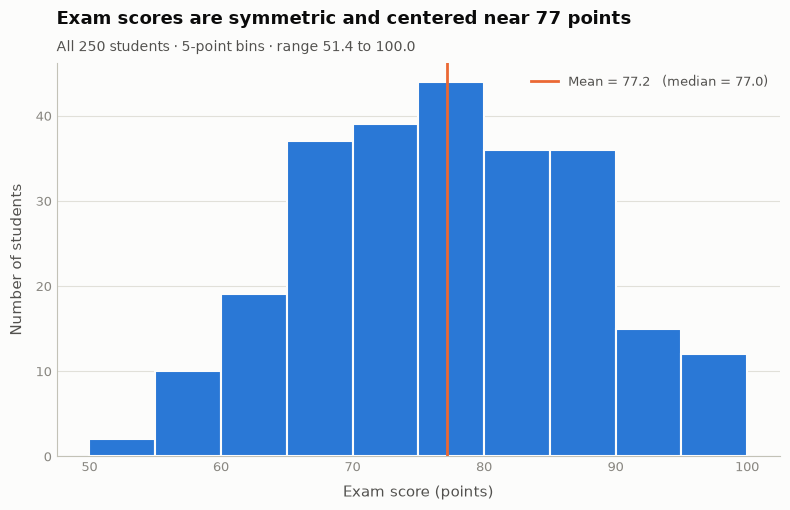

In [15]:
mean_exam = df["exam_score"].mean()
median_exam = df["exam_score"].median()

fig, ax = plt.subplots(figsize=(8, 5.2))

bins = np.arange(50, 105, 5)
ax.hist(df["exam_score"], bins=bins, color=BLUE,
        edgecolor=SURFACE, linewidth=1.5, zorder=3)   # surface gap, not a border

ax.axvline(mean_exam, color=ORANGE, linewidth=2, zorder=4,
           label=f"Mean = {mean_exam:.1f}   (median = {median_exam:.1f})")

style(ax,
      f"Exam scores are symmetric and centered near {mean_exam:.0f} points",
      f"All {df['exam_score'].notna().sum()} students · 5-point bins · "
      f"range {df['exam_score'].min():.1f} to {df['exam_score'].max():.1f}",
      "Exam score (points)",
      "Number of students")
ax.grid(False, axis="x")
style_legend(ax, "upper right")

fig.tight_layout()
plt.show()

**Histogram interpretation**

From this graph, I notice that the deviation from the median to 100, has a higher percentage of students than the median to the minimum score. The higher outliers are more prevalent than the low score outliers.

### Visualization 2: Study hours vs exam score

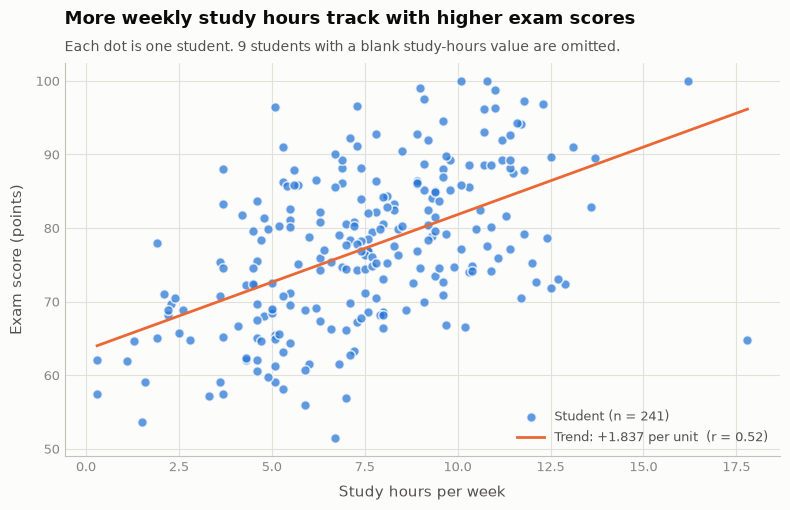

In [16]:
r_study = scatter_vs_exam(
    "study_hours_per_week",
    "More weekly study hours track with higher exam scores",
    "Each dot is one student. 9 students with a blank study-hours value are omitted.",
    "Study hours per week",
)

**Scatter plot interpretation**

From this graph, I notice that there is a general positive correlation between study hours per week and exam score. The data is still very spread out, and is not a tight correlation.

### Visualization 3: Sleep vs exam score

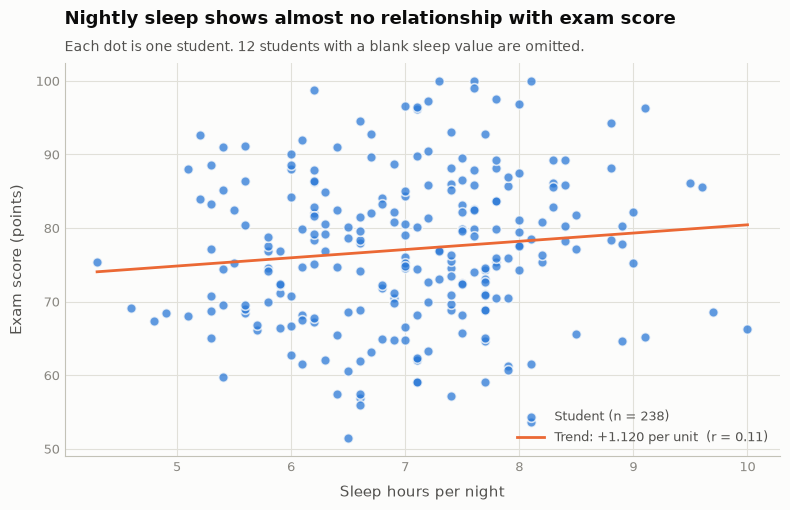

In [17]:
r_sleep = scatter_vs_exam(
    "sleep_hours_per_night",
    "Nightly sleep shows almost no relationship with exam score",
    "Each dot is one student. 12 students with a blank sleep value are omitted.",
    "Sleep hours per night",
)

**Sleep vs exam score interpretation**

From this graph, I notice that hours slept each night shows basically no correlation with exam score. Some students that have very little sleep, score similarly to those that sleep a lot each night.

In [18]:
header("WHAT THE TWO SCATTER PLOTS SHOW")
print(f"study_hours_per_week vs exam_score:  r = {r_study:+.3f}   "
      f"r^2 = {r_study ** 2:.3f}")
print(f"sleep_hours_per_night vs exam_score: r = {r_sleep:+.3f}   "
      f"r^2 = {r_sleep ** 2:.3f}")
print("\nr^2 is the share of variation in exam score that the habit accounts for.")
print("Neither plot establishes cause: these are observed habits, not assigned ones.")


WHAT THE TWO SCATTER PLOTS SHOW
study_hours_per_week vs exam_score:  r = +0.516   r^2 = 0.266
sleep_hours_per_night vs exam_score: r = +0.114   r^2 = 0.013

r^2 is the share of variation in exam score that the habit accounts for.
Neither plot establishes cause: these are observed habits, not assigned ones.


## Part 6: Investigating One Relationship (quiz average vs exam score)

**Prediction:** I expect that qui scores to be associated with exam scores because typically, quizzes cover all of the material that is to be on quizzes, so the better a student scores on quizzes, the better they know the information that will be on the exams

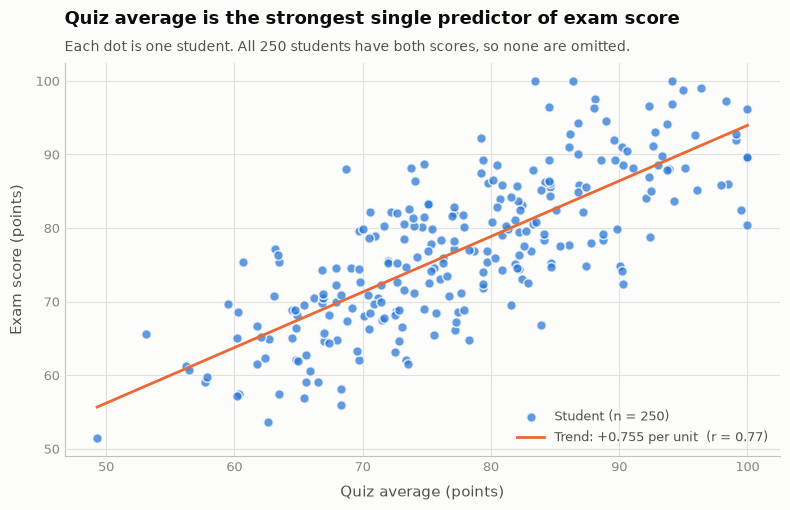

In [19]:
r_quiz = scatter_vs_exam(
    "quiz_average",
    "Quiz average is the strongest single predictor of exam score",
    "Each dot is one student. All 250 students have both scores, so none are omitted.",
    "Quiz average (points)",
)

In [20]:
header("CORRELATION: quiz_average vs exam_score")
print(f"Pearson r          = {r_quiz:+.3f}")
print(f"r squared          = {r_quiz ** 2:.3f}  "
      f"({r_quiz ** 2 * 100:.1f}% of exam-score variation accounted for)")
print(f"Students compared  = {df[['quiz_average', 'exam_score']].dropna().shape[0]}")

slope, intercept = np.polyfit(df["quiz_average"], df["exam_score"], 1)
residuals = df["exam_score"] - (slope * df["quiz_average"] + intercept)
print(f"\nFitted line        : exam = {slope:.3f} x quiz + {intercept:.2f}")
print(f"Typical miss       : {residuals.std():.2f} points "
      f"(std of the vertical distance from the line)")
print(f"\nInterpretation: 10 more quiz points corresponds to about "
      f"{slope * 10:.1f} more exam points on average,")
print("but individual students still land several points either side of that line.")


CORRELATION: quiz_average vs exam_score
Pearson r          = +0.769
r squared          = 0.591  (59.1% of exam-score variation accounted for)
Students compared  = 250

Fitted line        : exam = 0.755 x quiz + 18.43
Typical miss       : 6.61 points (std of the vertical distance from the line)

Interpretation: 10 more quiz points corresponds to about 7.6 more exam points on average,
but individual students still land several points either side of that line.


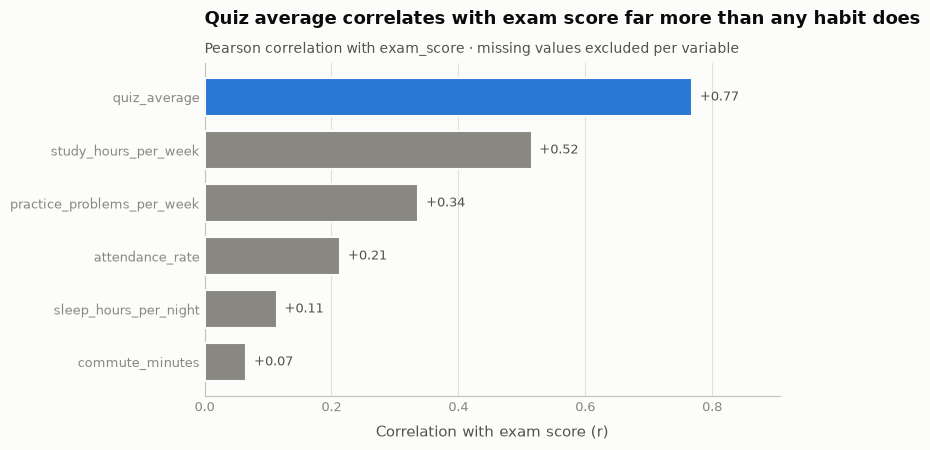

In [21]:
corrs = (df[numerical].drop(columns=["exam_score"])
         .corrwith(df["exam_score"])
         .sort_values())

fig, ax = plt.subplots(figsize=(8, 4.6))

# Emphasis, not a value ramp: the variable under investigation is highlighted,
# the rest recede to a neutral so the comparison reads at a glance.
colors = [BLUE if name == "quiz_average" else MUTED for name in corrs.index]
ax.barh(corrs.index, corrs.values, color=colors,
        edgecolor=SURFACE, linewidth=1.5, height=0.72, zorder=3)

for name, value in corrs.items():
    ax.text(value + 0.012, name, f"{value:+.2f}", va="center",
            fontsize=9.5, color=SECONDARY)

style(ax,
      "Quiz average correlates with exam score far more than any habit does",
      "Pearson correlation with exam_score · missing values excluded per variable",
      "Correlation with exam score (r)",
      "")
ax.grid(False, axis="y")
ax.set_xlim(0, max(corrs.values) * 1.18)

fig.tight_layout()
plt.show()

**Results**

It turns out, that quiz score is the best predictor for exam score. The quiz average vs exam average has the tightest spread and correlation. Therefore usually as quiz exam scores improve, so do exam scores. There's of course, always outliers, but the deviation is only 6.61 points on average. The pearson r value, which is the strength of the correlation, is 7.68. This is a large positive correlation.

## Part 7: Student-Designed Data Question (Commute Time vs Attendance)

**Question:** Do students who commute the most have better or worse attendance?

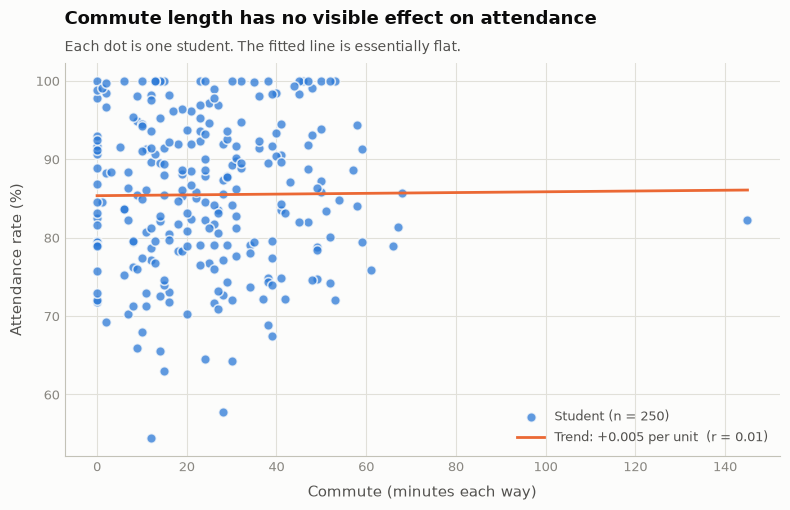


CORRELATION: commute_minutes vs attendance_rate
Pearson r    = +0.0094   (linear relationship)
r squared    = 0.0001   (0.01% of attendance variation accounted for)
Spearman rho = +0.0139   (rank relationship, robust to the skew)


In [22]:
r_commute = scatter_relationship(
    "commute_minutes", "attendance_rate",
    "Commute length has no visible effect on attendance",
    "Each dot is one student. The fitted line is essentially flat.",
    "Commute (minutes each way)",
    "Attendance rate (%)",
)

header("CORRELATION: commute_minutes vs attendance_rate")
print(f"Pearson r    = {r_commute:+.4f}   (linear relationship)")
print(f"r squared    = {r_commute ** 2:.4f}   "
      f"({r_commute ** 2 * 100:.2f}% of attendance variation accounted for)")

# Commute is right-skewed, so also check Spearman's rank correlation, which is
# not pulled by the long tail. Spearman is Pearson r computed on the ranks.
rho = df["commute_minutes"].rank().corr(df["attendance_rate"].rank())
print(f"Spearman rho = {rho:+.4f}   (rank relationship, robust to the skew)")


ATTENDANCE BY COMMUTE QUARTILE


,n_students,min_commute,max_commute,mean_attendance,median_attendance,mean_exam
commute_quartile,,,,,,
Q1 shortest,63,0,11,85.33,85.4,77.41
Q2,65,12,23,85.70,86.1,74.91
Q3,61,24,36,84.93,85.6,77.79
Q4 longest,61,37,145,85.91,85.7,78.67


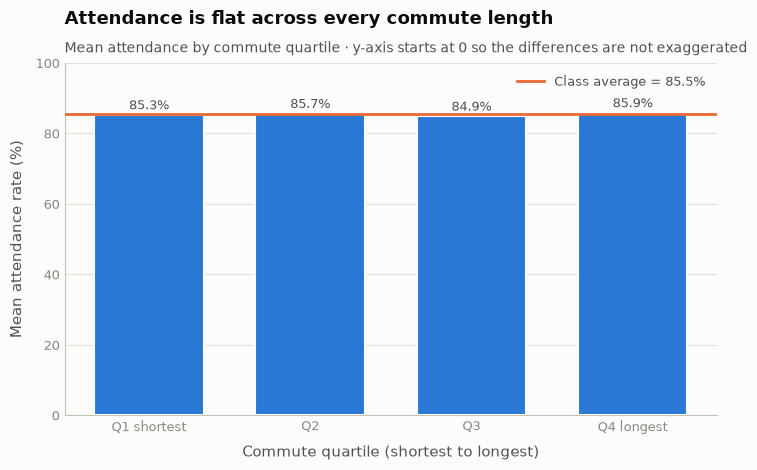

In [23]:
header("ATTENDANCE BY COMMUTE QUARTILE")

# Kept as a separate Series so df is not changed by this analysis.
commute_quartile = pd.qcut(
    df["commute_minutes"], 4,
    labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"],
).rename("commute_quartile")

by_commute = df.groupby(commute_quartile, observed=True).agg(
    n_students=("attendance_rate", "count"),
    min_commute=("commute_minutes", "min"),
    max_commute=("commute_minutes", "max"),
    mean_attendance=("attendance_rate", "mean"),
    median_attendance=("attendance_rate", "median"),
    mean_exam=("exam_score", "mean"),
).round(2)
display(by_commute)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(by_commute.index.astype(str), by_commute["mean_attendance"],
       color=BLUE, edgecolor=SURFACE, linewidth=1.5, width=0.68, zorder=3)

overall = df["attendance_rate"].mean()
ax.axhline(overall, color=ORANGE, linewidth=2, zorder=4,
           label=f"Class average = {overall:.1f}%")

for label, value in by_commute["mean_attendance"].items():
    ax.text(str(label), value + 1.5, f"{value:.1f}%", ha="center",
            fontsize=9.5, color=SECONDARY)

style(ax,
      "Attendance is flat across every commute length",
      "Mean attendance by commute quartile · y-axis starts at 0 so the "
      "differences are not exaggerated",
      "Commute quartile (shortest to longest)",
      "Mean attendance rate (%)")
ax.grid(False, axis="x")
ax.set_ylim(0, 100)          # full scale: a truncated axis would invent a trend
style_legend(ax, "upper right")

fig.tight_layout()
plt.show()

In [24]:
header("THE LONGEST COMMUTERS")
far = df[df["commute_minutes"] >= 60]
print(f"Students commuting 60+ minutes: n = {len(far)}")
print(f"  their mean attendance: {far['attendance_rate'].mean():.2f}%")
print(f"  class mean attendance: {df['attendance_rate'].mean():.2f}%")
print(f"  standard error on a group this small: "
      f"{df['attendance_rate'].std() / np.sqrt(len(far)):.2f} points")
print("\nThe gap is within the noise you expect from a group of this size,")
print("so it is not evidence of a real effect.")
display(far[["student_id", "commute_minutes", "attendance_rate",
             "study_hours_per_week", "exam_score"]]
        .sort_values("commute_minutes", ascending=False))


THE LONGEST COMMUTERS
Students commuting 60+ minutes: n = 5
  their mean attendance: 80.84%
  class mean attendance: 85.47%
  standard error on a group this small: 4.28 points

The gap is within the noise you expect from a group of this size,
so it is not evidence of a real effect.


column,student_id,commute_minutes,attendance_rate,study_hours_per_week,exam_score
17,S018,145,82.3,6.8,79.0
93,S094,68,85.7,10.1,85.8
192,S193,67,81.4,10.2,66.6
172,S173,66,78.9,6.3,67.4
162,S163,61,75.9,6.6,75.4


**My Conclusion**

Overall, commute time does not have any impact on class attendance. From my thoughts going in, I thought the students who commuted the most would have the most attendance, but I realize that this could be skewed by student having different distances to travel. For example, a student with 100% attendance could only live 5 minutes away, while a student with only 20% attendance might live multiple hours away, meaning that the 20% student could have commuted longer than the 100% student. 


## Part 8: AI Reflection

### Explained unfamiliar code

I think that AI was most helpful in understanding the pandas dataframe in general. 
At the beginning of the assignment, I thought that a pd dataframe was an advanced data structure, but AI explaining it to me clearly showed that it's just basically a spreadsheet of data.

Where instead of the spreadsheet being treated as just plain data, it's treated as a grouping of variables, with rows and columns containing a single data type of certain variability. 

Continuing through the assignment, and looking over the AI generated pd code, I realized that a lot of the methods are also very simple. I think that this specific way of storing information is probably the basis of feeding AI information, due to it's ease of use.

To verify the AI's information, I fact checked classic pandas formatting online, and also did a bit more research into the background of how AI models are trained, finding out they typically include dataframes like these, where they are trained on predicting filling in missing data.